# Fall 2026 Market Predictions — Scoring & Visualization

Visualizes the rankings of students based on their predictions from a supplied excel file.

In [1]:
import re
import math
import json
import time
import shutil
import urllib.request
import urllib.parse
from pathlib import Path
from datetime import datetime
import pytz

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"

In [ ]:
# --- Config ---
# All paths below are relative to the current working directory (cwd) the kernel was
# launched from, not to this notebook's file location. Launch Jupyter / open and run
# this notebook from the project folder that contains the Excel input file (the same
# folder this notebook itself lives in). If you don't, pd.read_excel(INPUT_FILE) below
# will fail fast with a clear FileNotFoundError naming the missing file -- it will not
# silently create results/ or old_results/ somewhere unexpected.

INPUT_FILE = Path("Fall 2026 Market Predictions (Responses).xlsx")
SHEET_NAME = "Predictions"
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
OLD_RESULTS_DIR = Path("old_results")
OLD_RESULTS_DIR.mkdir(exist_ok=True)
DATE_STAMP = datetime.now().strftime("%Y-%m-%d")  # appended to output filenames

# Archive whatever's already in results/ (a previous run's outputs) into old_results/
# before this run writes anything new, so results/ only ever holds the latest run.
# Overwrites a same-named file already in old_results/ (e.g. a second run on the same
# DATE_STAMP) rather than erroring, since it's archiving an equivalent re-run.
_archived = []
for _path in RESULTS_DIR.iterdir():
    if _path.is_file():
        _dest = OLD_RESULTS_DIR / _path.name
        if _dest.exists():
            _dest.unlink()
        shutil.move(str(_path), str(_dest))
        _archived.append(_path.name)
if _archived:
    print(f"Archived {len(_archived)} file(s) from a previous run to {OLD_RESULTS_DIR.name}/:")
    for _name in sorted(_archived):
        print(f" - {_name}")

# CONTROL is a synthetic "no change" baseline (its predictions are the anchor prices),
# not a competitor. When True, CONTROL is excluded from rank/leaderboard winners and
# from the standings heatmap, but still shown for reference. Set False to restore the
# old behavior of ranking CONTROL alongside everyone.
EXCLUDE_BENCHMARK_FROM_RANKS = True

# Colorblind-safe categorical colors (validated for 3-way comparisons)
CAT_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua
SEQ_COLOR = "#2a78d6"  # single-hue sequential (histograms)

In [3]:
# --- STEP 1: LOAD DATA ---

raw_df = pd.read_excel(INPUT_FILE, sheet_name=SHEET_NAME)
print(f"Loaded {len(raw_df)} responses with columns:")
print(list(raw_df.columns))
raw_df.head()

Loaded 52 responses with columns:
['Email Address', 'Your NetID', 'Last (family) name', 'First (given) name', 'S&P 500 Index (currently 7666)', 'MSCI World Index (MXWO) Developed Markets (currently 4944)', 'MSCI EM Index (MXEF) Emerging Markets (currently 1700)', '1 oz Gold (currently $4,440)', '1 Bitcoin (currently $78,000)', '1 barrel of WTI crude oil (currently $92)', 'JPY USD exchange rate (currently Y156)', 'US 10-year rate (currently 4.77%)']


,Email Address,Your NetID,Last (family) name,First (given) name,S&P 500 Index (currently 7666),MSCI World Index (MXWO) Developed Markets (currently 4944),MSCI EM Index (MXEF) Emerging Markets (currently 1700),"1 oz Gold (currently $4,440)","1 Bitcoin (currently $78,000)",1 barrel of WTI crude oil (currently $92),JPY USD exchange rate (currently Y156),US 10-year rate (currently 4.77%)
0,suditi.basak@emory.edu,sbasak4,Basak,Suditi,7698.0,5050.0,1800.0,4800.0,77000.0,94.0,154.0,4.65
1,paloma.beltran@emory.edu,APBELTR,Beltran,Paloma,7900.0,5100.0,1650.0,4550.0,72000.0,100.0,152.0,4.90
2,usher.boisvert@emory.edu,uboisve,Boisvert,Usher,7583.0,4786.0,1460.0,4690.0,87000.0,70.0,149.0,5.00
3,henri.bonnault@emory.edu,hbonau,Bonnault,Henri,7900.0,5150.0,1800.0,4900.0,95000.0,80.0,157.0,4.85
4,riyze.booker@emory.edu,bbooke3,Booker,Riyze,7900.0,5100.0,1780.0,4750.0,85000.0,95.0,153.0,4.90


In [4]:
# --- STEP 2: BUILD PARTICIPANTS (columns C-D) AND IDENTIFY ASSET COLUMNS (columns E-L) ---
# "Group" is excluded here too (not just the four ID columns) so that if the sheet ever
# adds a Group column, it isn't silently absorbed as a ninth asset.

LAST_COL, FIRST_COL, GROUP_COL = "Last (family) name", "First (given) name", "Group"
NON_ASSET_COLS = ("Email Address", "Your NetID", LAST_COL, FIRST_COL, GROUP_COL)
asset_raw_cols = [c for c in raw_df.columns if c not in NON_ASSET_COLS]

df = raw_df.copy()

# Drop fully blank rows (no prediction for any asset) before anything else -- a stray
# blank/malformed submission would otherwise get a Total_Rank_Score of 0.0 in STEP 6
# (pandas sums an all-NaN row to 0, not NaN) and falsely "win" the rank-score leaderboard.
blank_mask = df[asset_raw_cols].isna().all(axis=1)
if blank_mask.any():
    print("\n" + "!" * 72)
    print(f"WARNING: {blank_mask.sum()} row(s) have no prediction for ANY asset "
          "(blank/malformed submission) and are being dropped before scoring:")
    print(df.loc[blank_mask, ["Email Address", "Your NetID"]].to_string(index=False))
    print("!" * 72 + "\n")
    df = df[~blank_mask].reset_index(drop=True)

last = df[LAST_COL].astype(str).str.strip()
first = df[FIRST_COL].astype(str).str.strip()

is_control = (last.str.upper() == "CONTROL") & (first.str.upper() == "CONTROL")
df["Person"] = np.where(is_control, "CONTROL", first + " " + last)

# Group: "benchmark" (CONTROL, the synthetic no-change baseline) vs "student" (everyone
# else -- including guests like the professor's family, who compete normally). The sheet
# doesn't have a Group column yet, so it's synthesized; if one is added later, it's
# trusted as-is (only truly blank cells default to "student").
if GROUP_COL in raw_df.columns:
    group = df[GROUP_COL].astype(str).str.strip()
    df["Group"] = group.mask(group.eq("") | group.str.lower().eq("nan"), "student")
else:
    df["Group"] = np.where(is_control, "benchmark", "student")

PERSON_GROUP = dict(zip(df["Person"], df["Group"]))

dupes = df["Person"][df["Person"].duplicated(keep=False)]
if not dupes.empty:
    print("Warning: duplicate Person values found, please review:")
    print(sorted(dupes.unique()))

print(f"Participants: {df['Person'].nunique()}")
print(f"Asset columns ({len(asset_raw_cols)}):")
for c in asset_raw_cols:
    print(" -", c)


!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
Email Address Your NetID
           51        NaN
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

Participants: 51
Asset columns (8):
 - S&P 500 Index (currently 7666)
 - MSCI World Index (MXWO) Developed Markets (currently 4944)
 - MSCI EM Index (MXEF) Emerging Markets (currently 1700)
 - 1 oz Gold (currently $4,440)
 - 1 Bitcoin (currently $78,000)
 - 1 barrel of WTI crude oil (currently $92)
 - JPY USD exchange rate (currently Y156)
 - US 10-year rate (currently 4.77%)


In [5]:
# --- STEP 3: PARSE ASSET LABELS + ANCHOR ("currently ...") PRICES FROM HEADERS ---

ANCHOR_RE = re.compile(r"currently\s*[\$Y]?([\d,]+\.?\d*)\s*%?\)", re.IGNORECASE)


def parse_asset_column(col_name):
    label = re.split(r"\s*\(currently", col_name, flags=re.IGNORECASE)[0]
    label = re.sub(r"\([^)]*\)", "", label)  # drop any other parentheticals, e.g. (MXWO)
    label = re.sub(r"\s+", " ", label).strip()
    m = ANCHOR_RE.search(col_name)
    anchor_price = float(m.group(1).replace(",", "")) if m else None
    return label, anchor_price


asset_info = pd.DataFrame(
    [(col, *parse_asset_column(col)) for col in asset_raw_cols],
    columns=["raw_column", "label", "anchor_price"],
)
asset_info

,raw_column,label,anchor_price
0,S&P 500 Index (currently 7666),S&P 500 Index,7666.00
1,MSCI World Index (MXWO) Developed Markets (cur...,MSCI World Index Developed Markets,4944.00
2,MSCI EM Index (MXEF) Emerging Markets (current...,MSCI EM Index Emerging Markets,1700.00
3,"1 oz Gold (currently $4,440)",1 oz Gold,4440.00
4,"1 Bitcoin (currently $78,000)",1 Bitcoin,78000.00
5,1 barrel of WTI crude oil (currently $92),1 barrel of WTI crude oil,92.00
6,JPY USD exchange rate (currently Y156),JPY USD exchange rate,156.00
7,US 10-year rate (currently 4.77%),US 10-year rate,4.77


### Actual / current prices

`ACTUAL_PRICES` is fetched **live (or last close, if markets are currently closed)** from Yahoo Finance at the moment this notebook runs, via `TICKER_MAP` below. It no longer defaults to the anchor values embedded in the survey headers under any circumstance: if a ticker fails on every retry across both Yahoo hosts, that asset is **dropped from this run's scoring** (not substituted with the anchor) and called out in a banner — falling back to the anchor would silently hand CONTROL a 0.00% APE on that asset, since CONTROL's predictions are the anchor values by construction.

Two tickers are proxies rather than exact matches, noted here rather than left implicit:
- **1 oz Gold** → `GC=F` (COMEX gold futures, front month) — the standard free-data stand-in for spot gold; close but not always identical to true spot.
- **1 barrel of WTI crude oil** → `CL=F` (NYMEX WTI futures, front month) — the conventional quote for "the price of WTI."

Everything else (S&P 500, MSCI World/EM index levels, Bitcoin, JPY/USD, US 10-year yield) maps to a direct index/spot ticker.

In [6]:
# --- FETCH LIVE / LAST-CLOSE PRICES (Yahoo Finance chart API) ---
# CONTROL's predictions are literally the anchor prices baked into the survey headers,
# so silently falling back to the anchor on a fetch failure would hand CONTROL a free
# 0.00% APE and an automatic win. Instead, per asset:
#   1) up to 3 attempts against query1.finance.yahoo.com, backing off ~1s then ~2s
#      between attempts (Yahoo 429s are usually transient)
#   2) if every query1 attempt fails, the same retry policy against
#      query2.finance.yahoo.com (same API, different host)
#   3) if every attempt on both hosts fails, the asset is DROPPED from ACTUAL_PRICES
#      entirely (not set to None, not set to the anchor) -- this shrinks the scoring
#      denominator equally for every participant instead of biasing the leaderboard
#      toward whoever happened to guess near a stale anchor value.

TICKER_MAP = {
    "S&P 500 Index": "^GSPC",
    "MSCI World Index Developed Markets": "^990100-USD-STRD",  # MSCI World, Standard (price) index
    "MSCI EM Index Emerging Markets": "^891800-USD-STRD",      # MSCI EM, Standard (price) index
    "1 oz Gold": "GC=F",                                       # COMEX gold futures, front month (spot proxy)
    "1 Bitcoin": "BTC-USD",
    "1 barrel of WTI crude oil": "CL=F",                       # NYMEX WTI futures, front month
    "JPY USD exchange rate": "JPY=X",                          # yen per 1 USD
    "US 10-year rate": "^TNX",                                 # already quoted in percent, no scaling needed
}

YAHOO_HOSTS = ["query1.finance.yahoo.com", "query2.finance.yahoo.com"]
MAX_ATTEMPTS_PER_HOST = 3
RETRY_BACKOFF_SECONDS = [1, 2]  # sleep between attempt 1->2 and 2->3

_USER_AGENT = "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36"


def _is_market_open():
    """Check if US stock market is currently open (9:30 AM - 4 PM ET, weekdays only)."""
    et = pytz.timezone("US/Eastern")
    now = datetime.now(et)
    # Market is open Mon-Fri, 9:30 AM - 4 PM ET. Compare (hour, minute) tuples, not
    # a float hour -- `9.5 <= now.hour` is never true for hour==9, which misclassified
    # 9:30-9:59 AM ET as closed.
    return now.weekday() < 5 and (9, 30) <= (now.hour, now.minute) < (16, 0)


def _fetch_yahoo_price_once(host, ticker, timeout=10):
    """Fetch chart data and return (intraday_price, close_price, timestamp) or raise on failure."""
    url = f"https://{host}/v8/finance/chart/{urllib.parse.quote(ticker)}?range=5d&interval=1d"
    req = urllib.request.Request(url, headers={"User-Agent": _USER_AGENT})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        payload = json.loads(resp.read())
    
    meta = payload["chart"]["result"][0]["meta"]
    chart = payload["chart"]["result"][0]
    
    intraday_price = meta["regularMarketPrice"]
    
    # Get close price from the most recent bar
    timestamps = chart["timestamp"]
    closes = chart["indicators"]["quote"][0]["close"]
    most_recent_close = closes[-1] if closes[-1] is not None else closes[-2]
    most_recent_timestamp = timestamps[-1]
    
    return intraday_price, most_recent_close, most_recent_timestamp


def fetch_yahoo_price(ticker):
    """Fetch price: intraday if markets are open, close price if closed.
    
    Returns (price, host) on success, or (None, None) if every attempt on every host failed.
    """
    for host in YAHOO_HOSTS:
        for attempt in range(MAX_ATTEMPTS_PER_HOST):
            try:
                intraday_price, close_price, timestamp = _fetch_yahoo_price_once(host, ticker)
                
                # Decide which price to use based on market hours
                if _is_market_open():
                    return intraday_price, host
                else:
                    return close_price, host
                    
            except Exception as e:
                print(f"  Warning: fetch attempt {attempt + 1}/{MAX_ATTEMPTS_PER_HOST} "
                      f"for {ticker!r} via {host} failed ({e}).")
                if attempt < MAX_ATTEMPTS_PER_HOST - 1:
                    time.sleep(RETRY_BACKOFF_SECONDS[attempt])
    return None, None


ACTUAL_PRICES = {}
price_source = {}
dropped_assets = []
print("Fetching live/last-close prices from Yahoo Finance...")
market_status = "OPEN (using intraday prices)" if _is_market_open() else "CLOSED (using close prices)"
print(f"Market status: {market_status}\n")

for _, row in asset_info.iterrows():
    label, anchor = row["label"], row["anchor_price"]
    ticker = TICKER_MAP.get(label)
    if ticker is None:
        print(f"  Warning: no ticker mapped for {label!r} -- asset dropped, no fetch attempted.")
        price_source[label] = "FETCH FAILED - asset dropped"
        dropped_assets.append(label)
        continue
    live_price, host = fetch_yahoo_price(ticker)
    if live_price is not None:
        ACTUAL_PRICES[label] = live_price
        price_type = "intraday" if _is_market_open() else "close"
        price_source[label] = f"{price_type} ({ticker} via {host.split('.')[0]})"
    else:
        price_source[label] = "FETCH FAILED - asset dropped"
        dropped_assets.append(label)

if dropped_assets:
    print("\n" + "=" * 72)
    print("WARNING: the following assets could NOT be fetched from Yahoo Finance on")
    print("ANY host after retries, and have been DROPPED from this run's scoring")
    print("entirely (never scored against a stale anchor price):")
    for label in dropped_assets:
        print(f"  - {label}")
    # len(asset_info), not len(TICKER_MAP): an unmapped label lands in dropped_assets
    # without ever being a TICKER_MAP entry, which would under-count both sides.
    print(f"This run's leaderboard is scored over {len(asset_info) - len(dropped_assets)} "
          f"of {len(asset_info)} assets.")
    print("=" * 72 + "\n")

price_check = asset_info[["label", "anchor_price"]].copy()
price_check["ticker"] = price_check["label"].map(TICKER_MAP)
price_check["actual_price"] = price_check["label"].map(ACTUAL_PRICES)
price_check["source"] = price_check["label"].map(price_source)
price_check

# Manual override, if ever needed (e.g. a ticker is temporarily wrong/delisted):
# ACTUAL_PRICES["1 Bitcoin"] = 71190.70

Fetching live/last-close prices from Yahoo Finance...
Market status: OPEN (using intraday prices)



,label,anchor_price,ticker,actual_price,source
0,S&P 500 Index,7666.00,^GSPC,7645.200,intraday (^GSPC via query1)
1,MSCI World Index Developed Markets,4944.00,^990100-USD-STRD,4897.570,intraday (^990100-USD-STRD via query1)
2,MSCI EM Index Emerging Markets,1700.00,^891800-USD-STRD,1575.320,intraday (^891800-USD-STRD via query1)
3,1 oz Gold,4440.00,GC=F,3998.000,intraday (GC=F via query1)
4,1 Bitcoin,78000.00,BTC-USD,74336.970,intraday (BTC-USD via query1)
5,1 barrel of WTI crude oil,92.00,CL=F,86.960,intraday (CL=F via query1)
6,JPY USD exchange rate,156.00,JPY=X,159.884,intraday (JPY=X via query1)
7,US 10-year rate,4.77,^TNX,4.998,intraday (^TNX via query1)


In [7]:
# --- STEP 4: BUILD RESULTS TABLE (PREDICTIONS + APE PER ASSET) ---

col_to_label = dict(zip(asset_info["raw_column"], asset_info["label"]))
assets = list(asset_info["label"])

results_df = df.set_index("Person")[list(col_to_label)].rename(columns=col_to_label)
results_df = results_df.add_suffix("_Pred")

ape_columns = []
for asset in assets:
    actual_price = ACTUAL_PRICES.get(asset)
    if actual_price is None:
        print(f"Warning: no actual price for {asset}, skipping.")
        continue
    ape_col = f"{asset}_APE"
    results_df[ape_col] = (results_df[f"{asset}_Pred"] - actual_price).abs() / actual_price
    ape_columns.append(ape_col)

scored_assets = [a for a in assets if a in ACTUAL_PRICES]
if not scored_assets:
    raise RuntimeError(
        "No assets have an actual price this run (every ticker fetch failed) -- "
        "cannot compute a leaderboard. See the fetch-failure banner above."
    )

results_df["Average_APE"] = results_df[ape_columns].mean(axis=1)
results_df.sort_values("Average_APE", ascending=True, inplace=True)

# CONTROL is a benchmark, not a competitor: the printed Winner is the top participant
# with Group != "benchmark", though CONTROL stays visible in results_df/the leaderboard.
if EXCLUDE_BENCHMARK_FROM_RANKS:
    competitors = results_df[[PERSON_GROUP.get(p) != "benchmark" for p in results_df.index]]
else:
    competitors = results_df

winner = competitors.index[0]
winning_score = competitors.iloc[0]["Average_APE"]
print(f"Winner: {winner} with an Average APE of {winning_score:.4%}\n")

display_cols = ["Average_APE"] + ape_columns
results_df[display_cols].head(10).style.format("{:.2%}")

Winner: Mason Burdyck with an Average APE of 4.7553%



,Average_APE,S&P 500 Index_APE,MSCI World Index Developed Markets_APE,MSCI EM Index Emerging Markets_APE,1 oz Gold_APE,1 Bitcoin_APE,1 barrel of WTI crude oil_APE,JPY USD exchange rate_APE,US 10-year rate_APE
Person,,,,,,,,,
CONTROL,4.74%,0.27%,0.95%,7.91%,11.06%,4.93%,5.80%,2.43%,4.56%
Mason Burdyck,4.76%,3.59%,3.15%,4.74%,14.81%,7.79%,0.05%,0.55%,3.36%
Suhaan Patel,5.12%,0.59%,0.97%,11.09%,11.31%,5.83%,0.05%,1.18%,9.96%
Muhammad Syed,5.65%,0.59%,0.97%,7.91%,11.31%,1.80%,3.50%,6.18%,12.97%
Abdur Rehman,5.71%,1.76%,4.13%,11.09%,15.06%,10.31%,2.25%,0.07%,1.04%
Aaron George,5.95%,3.14%,2.87%,10.52%,12.56%,8.18%,2.35%,3.05%,4.96%
Danny Schmidt,6.33%,4.52%,4.03%,1.57%,20.06%,7.62%,6.95%,4.93%,0.96%
Paloma Beltran,6.38%,3.33%,4.13%,4.74%,13.81%,3.14%,15.00%,4.93%,1.96%
Aleksi UyHam,6.86%,1.02%,2.09%,11.13%,14.06%,2.24%,12.60%,9.31%,2.44%


In [8]:
# Full leaderboard
results_df[display_cols].style.format("{:.2%}")

,Average_APE,S&P 500 Index_APE,MSCI World Index Developed Markets_APE,MSCI EM Index Emerging Markets_APE,1 oz Gold_APE,1 Bitcoin_APE,1 barrel of WTI crude oil_APE,JPY USD exchange rate_APE,US 10-year rate_APE
Person,,,,,,,,,
CONTROL,4.74%,0.27%,0.95%,7.91%,11.06%,4.93%,5.80%,2.43%,4.56%
Mason Burdyck,4.76%,3.59%,3.15%,4.74%,14.81%,7.79%,0.05%,0.55%,3.36%
Suhaan Patel,5.12%,0.59%,0.97%,11.09%,11.31%,5.83%,0.05%,1.18%,9.96%
Muhammad Syed,5.65%,0.59%,0.97%,7.91%,11.31%,1.80%,3.50%,6.18%,12.97%
Abdur Rehman,5.71%,1.76%,4.13%,11.09%,15.06%,10.31%,2.25%,0.07%,1.04%
Aaron George,5.95%,3.14%,2.87%,10.52%,12.56%,8.18%,2.35%,3.05%,4.96%
Danny Schmidt,6.33%,4.52%,4.03%,1.57%,20.06%,7.62%,6.95%,4.93%,0.96%
Paloma Beltran,6.38%,3.33%,4.13%,4.74%,13.81%,3.14%,15.00%,4.93%,1.96%
Aleksi UyHam,6.86%,1.02%,2.09%,11.13%,14.06%,2.24%,12.60%,9.31%,2.44%


In [9]:
# --- STEP 5: SIGNED ERRORS (FOR BIAS DIRECTION) ---

signed_error_data = {}
for asset in assets:
    actual_price = ACTUAL_PRICES.get(asset)
    pred_col = f"{asset}_Pred"
    if actual_price is not None and pred_col in results_df.columns:
        signed_error_data[asset] = (results_df[pred_col] - actual_price) / actual_price

signed_error_df = pd.DataFrame(signed_error_data, index=results_df.index)

avg_bias = signed_error_df.mean(axis=1)
avg_ape = results_df["Average_APE"]

plot_data = signed_error_df.copy()
plot_data["Average APE"] = avg_ape * np.sign(avg_bias)

annot_data = signed_error_df.copy()
annot_data["Average APE"] = avg_ape

cols = ["Average APE"] + list(signed_error_df.columns)
plot_data = plot_data[cols]
annot_data = annot_data[cols]

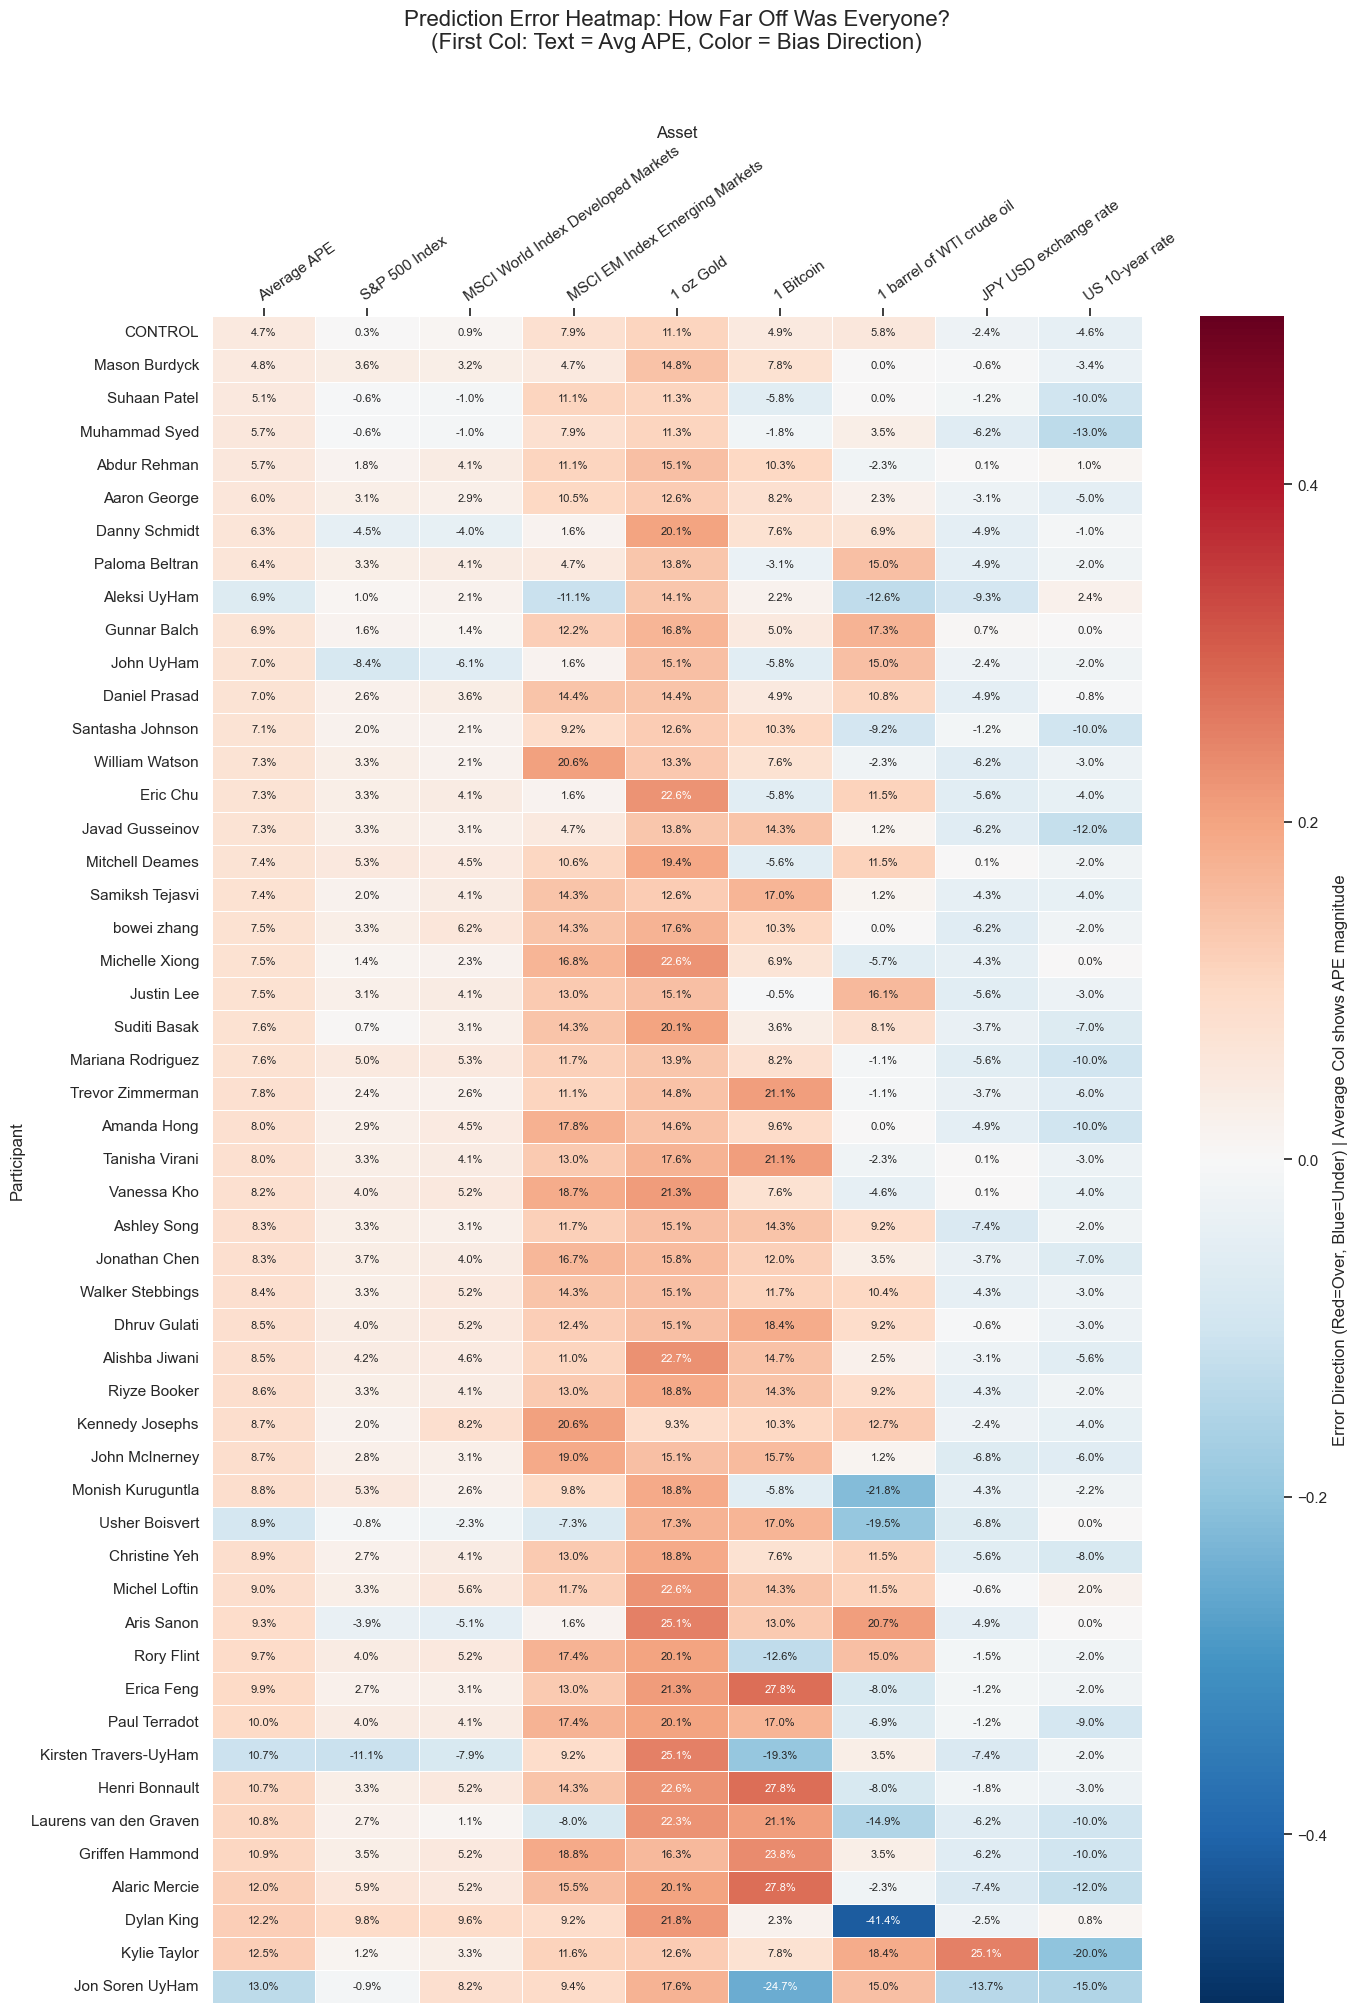

In [10]:
# --- VISUALIZATION 1: Prediction Error Heatmap (APE + bias direction) ---

n_people = len(plot_data)
fig_height = max(10, 0.3 * n_people + 5)

plt.figure(figsize=(14, fig_height))
ax = sns.heatmap(
    plot_data, annot=annot_data, fmt=".1%", cmap="RdBu_r", center=0,
    vmin=-0.5, vmax=0.5,
    cbar_kws={"label": "Error Direction (Red=Over, Blue=Under) | Average Col shows APE magnitude"},
    linewidths=0.5, annot_kws={"size": 8},
)
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
plt.setp(ax.get_xticklabels(), rotation=35, ha="left", rotation_mode="anchor")
plt.title(
    "Prediction Error Heatmap: How Far Off Was Everyone?\n"
    "(First Col: Text = Avg APE, Color = Bias Direction)",
    fontsize=16, pad=55,
)
plt.xlabel("Asset")
plt.ylabel("Participant")
plt.tight_layout()
plt.savefig(RESULTS_DIR / f"prediction_error_heatmap_{DATE_STAMP}.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# --- STEP 6: RANK-BASED STANDINGS ---
# When EXCLUDE_BENCHMARK_FROM_RANKS is set, ranks and Total_Rank_Score are computed over
# students only, so CONTROL occupying a slot never shifts anyone's displayed rank by one.
# CONTROL's own rank score (needed only to report where it would have placed) is computed
# separately, ranked against everyone -- exactly like the old, ungated behavior did.

if EXCLUDE_BENCHMARK_FROM_RANKS:
    competitor_index = [p for p in results_df.index if PERSON_GROUP.get(p) != "benchmark"]
else:
    competitor_index = list(results_df.index)

rankings_data = {}
for col in ape_columns:
    asset = col.replace("_APE", "")
    rankings_data[asset] = results_df.loc[competitor_index, col].rank(ascending=True)

rankings_df = pd.DataFrame(rankings_data, index=competitor_index)

# Full-field ranks (everyone, including CONTROL) on a single consistent scale -- used by
# the "would place" comparison below and, optionally, by Visualization 2 when it shows
# CONTROL. Kept separate from rankings_df (competitor-only) rather than mixed, since
# comparing ranks computed over different-sized fields isn't apples to apples (see the
# "would place" note just below).
full_rankings_data = {}
for col in ape_columns:
    asset = col.replace("_APE", "")
    full_rankings_data[asset] = results_df[col].rank(ascending=True)
full_rankings_df = pd.DataFrame(full_rankings_data, index=results_df.index)

rank_standings = rankings_df.copy()
rank_standings["Total_Rank_Score"] = rank_standings.sum(axis=1)
rank_standings.sort_values("Total_Rank_Score", ascending=True, inplace=True)

rank_winner = rank_standings.index[0]
rank_winning_score = rank_standings.iloc[0]["Total_Rank_Score"]
print(f"Winner based on Lowest Total Rank Score: {rank_winner} with a score of {rank_winning_score:.0f}\n")

if EXCLUDE_BENCHMARK_FROM_RANKS and "CONTROL" in results_df.index:
    # "Would place" must compare apples to apples: rank_standings' Total_Rank_Score is
    # computed over competitors ONLY (49 people), so ranks there are systematically lower
    # than a full-field (50-person, including CONTROL) ranking would give -- by exactly the
    # number of assets on which CONTROL beat that competitor. Comparing the competitor-only
    # sum against a full-field benchmark_rank_score silently overstates how well CONTROL
    # placed. Instead, rank everyone together once and compare on that single full-field scale.
    full_rank_sums = full_rankings_df.sum(axis=1)
    benchmark_rank_score = full_rank_sums.loc["CONTROL"]

    benchmark_ape = results_df.loc["CONTROL", "Average_APE"]
    ape_place = (results_df.loc[competitor_index, "Average_APE"] < benchmark_ape).sum() + 1
    rank_place = (full_rank_sums.loc[competitor_index] < benchmark_rank_score).sum() + 1
    n_competitors = len(competitor_index)
    print(f"Benchmark (CONTROL) would place {ape_place} of {n_competitors} by Average APE, "
          f"{rank_place} of {n_competitors} by rank score.\n")

rank_standings[["Total_Rank_Score"]]

Winner based on Lowest Total Rank Score: Suhaan Patel with a score of 92

Benchmark (CONTROL) would place 1 of 50 by Average APE, 1 of 50 by rank score.



,Total_Rank_Score
Suhaan Patel,92.5
Muhammad Syed,121.5
Abdur Rehman,124.5
Gunnar Balch,129.5
Mason Burdyck,130.0
Santasha Johnson,140.0
Aaron George,142.0
Aleksi UyHam,154.0
Paloma Beltran,160.0
Daniel Prasad,161.0


In [ ]:
# --- VISUALIZATION 2: Error Heatmap Sorted by Rank ---
# Leftmost column is a composite: its TEXT (from rankings_plot) is average per-asset RANK,
# while its COLOR (from sorted_error_df) is average SIGNED ERROR -- these are two different
# quantities sharing one column, matching the rest of this chart's rank-text/error-color
# convention. Neither is "Average APE" from the heatmap above.

# Show CONTROL in this heatmap for reference, even when EXCLUDE_BENCHMARK_FROM_RANKS
# excludes it from Total_Rank_Score/winner in STEP 6. When shown, ranks for EVERYONE in
# this chart switch to the full-field scale (full_rankings_df) so CONTROL's numbers sit
# on the same scale as everyone else's -- mixing a competitor-only rank scale with a
# full-field one for just CONTROL's row would misrepresent relative standing.
INCLUDE_CONTROL_IN_HEATMAP = True

use_full_field = INCLUDE_CONTROL_IN_HEATMAP and "CONTROL" in results_df.index
heatmap_rankings_df = (full_rankings_df if use_full_field else rankings_df).copy()

heatmap_rankings_df["Sum_Ranks"] = heatmap_rankings_df.sum(axis=1)
heatmap_rankings_df.sort_values("Sum_Ranks", ascending=True, inplace=True)

AGG_COL = "Avg Rank / Signed Err"
rankings_plot = heatmap_rankings_df.drop(columns=["Sum_Ranks"])
rankings_plot[AGG_COL] = rankings_plot.mean(axis=1)
annot_cols = [AGG_COL] + [c for c in rankings_plot.columns if c != AGG_COL]
rankings_plot = rankings_plot[annot_cols]

sorted_error_df = signed_error_df.reindex(heatmap_rankings_df.index)
sorted_error_df[AGG_COL] = sorted_error_df.mean(axis=1)
sorted_error_df = sorted_error_df[annot_cols]

fig_height2 = max(12, 0.4 * len(heatmap_rankings_df) + 5)
plt.figure(figsize=(12, fig_height2))
ax = sns.heatmap(
    sorted_error_df, annot=rankings_plot, fmt=".0f", cmap="RdBu_r",
    vmin=-0.2, vmax=0.2,
    cbar_kws={"label": "Signed Percentage Error (Color)", "shrink": 0.5},
    linewidths=1, linecolor="white", annot_kws={"size": 10},
)
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
plt.setp(ax.get_xticklabels(), rotation=35, ha="left", rotation_mode="anchor")
subtitle = "(Color = Error Direction, Text = Rank #; leftmost col = Avg Rank (text) / Avg Signed Error (color), not Avg APE)"
if use_full_field:
    subtitle += "\nCONTROL (benchmark) included for reference -- ranks here are full-field, so they may differ by up to 1 from STEP 6's Total_Rank_Score"
elif EXCLUDE_BENCHMARK_FROM_RANKS:
    subtitle += "\nCONTROL (benchmark) excluded from this view -- see \"would place\" line in STEP 6"
plt.title(
    f"Prediction Analysis Heatmap (Sorted by Standings)\n{subtitle}",
    fontsize=16, pad=70,
)
plt.xlabel("Asset", fontsize=12)
plt.ylabel("Participant (Ordered by Total Score)", fontsize=12)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / f"rank_heatmap_{DATE_STAMP}.png", dpi=150, bbox_inches="tight")
plt.show()

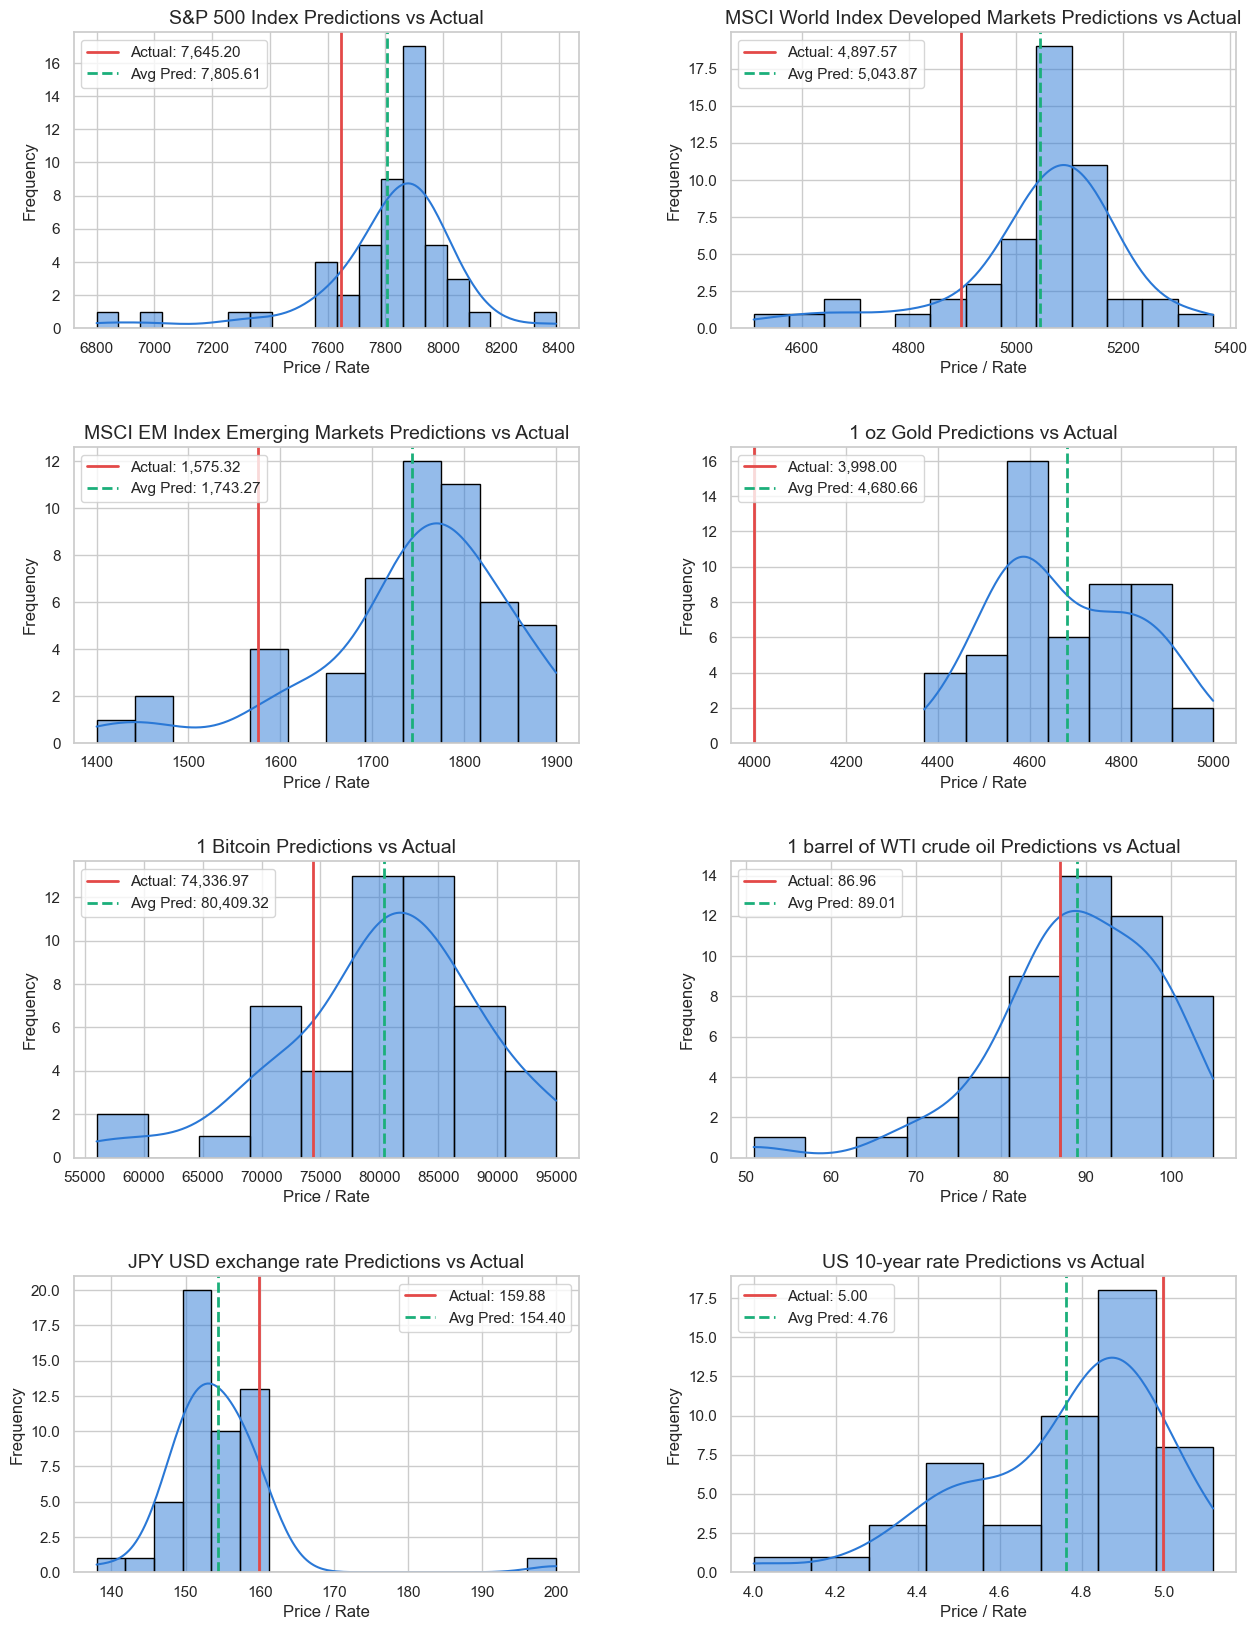

In [13]:
# --- VISUALIZATION 3: Predictions vs Actual (Distribution Plots) ---

n_assets = len(assets)
n_cols = 2
n_rows = math.ceil(n_assets / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
axes = np.atleast_1d(axes).flatten()

for i, asset in enumerate(assets):
    ax = axes[i]
    actual_price = ACTUAL_PRICES.get(asset)
    pred_col = f"{asset}_Pred"

    if actual_price is not None and pred_col in results_df.columns:
        sns.histplot(results_df[pred_col], kde=True, ax=ax, color=SEQ_COLOR, edgecolor="black")
        ax.axvline(actual_price, color="#e34948", linestyle="-", linewidth=2, label=f"Actual: {actual_price:,.2f}")
        avg_pred = results_df[pred_col].mean()
        ax.axvline(avg_pred, color="#1baf7a", linestyle="--", linewidth=2, label=f"Avg Pred: {avg_pred:,.2f}")
        ax.set_title(f"{asset} Predictions vs Actual", fontsize=14)
        ax.set_xlabel("Price / Rate")
        ax.set_ylabel("Frequency")
        ax.legend()
    else:
        ax.text(0.5, 0.5, "Data Not Available", ha="center", va="center")
        ax.set_title(asset)

for j in range(n_assets, len(axes)):
    axes[j].axis("off")

plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig(RESULTS_DIR / f"prediction_distributions_{DATE_STAMP}.png", dpi=150, bbox_inches="tight")
plt.show()

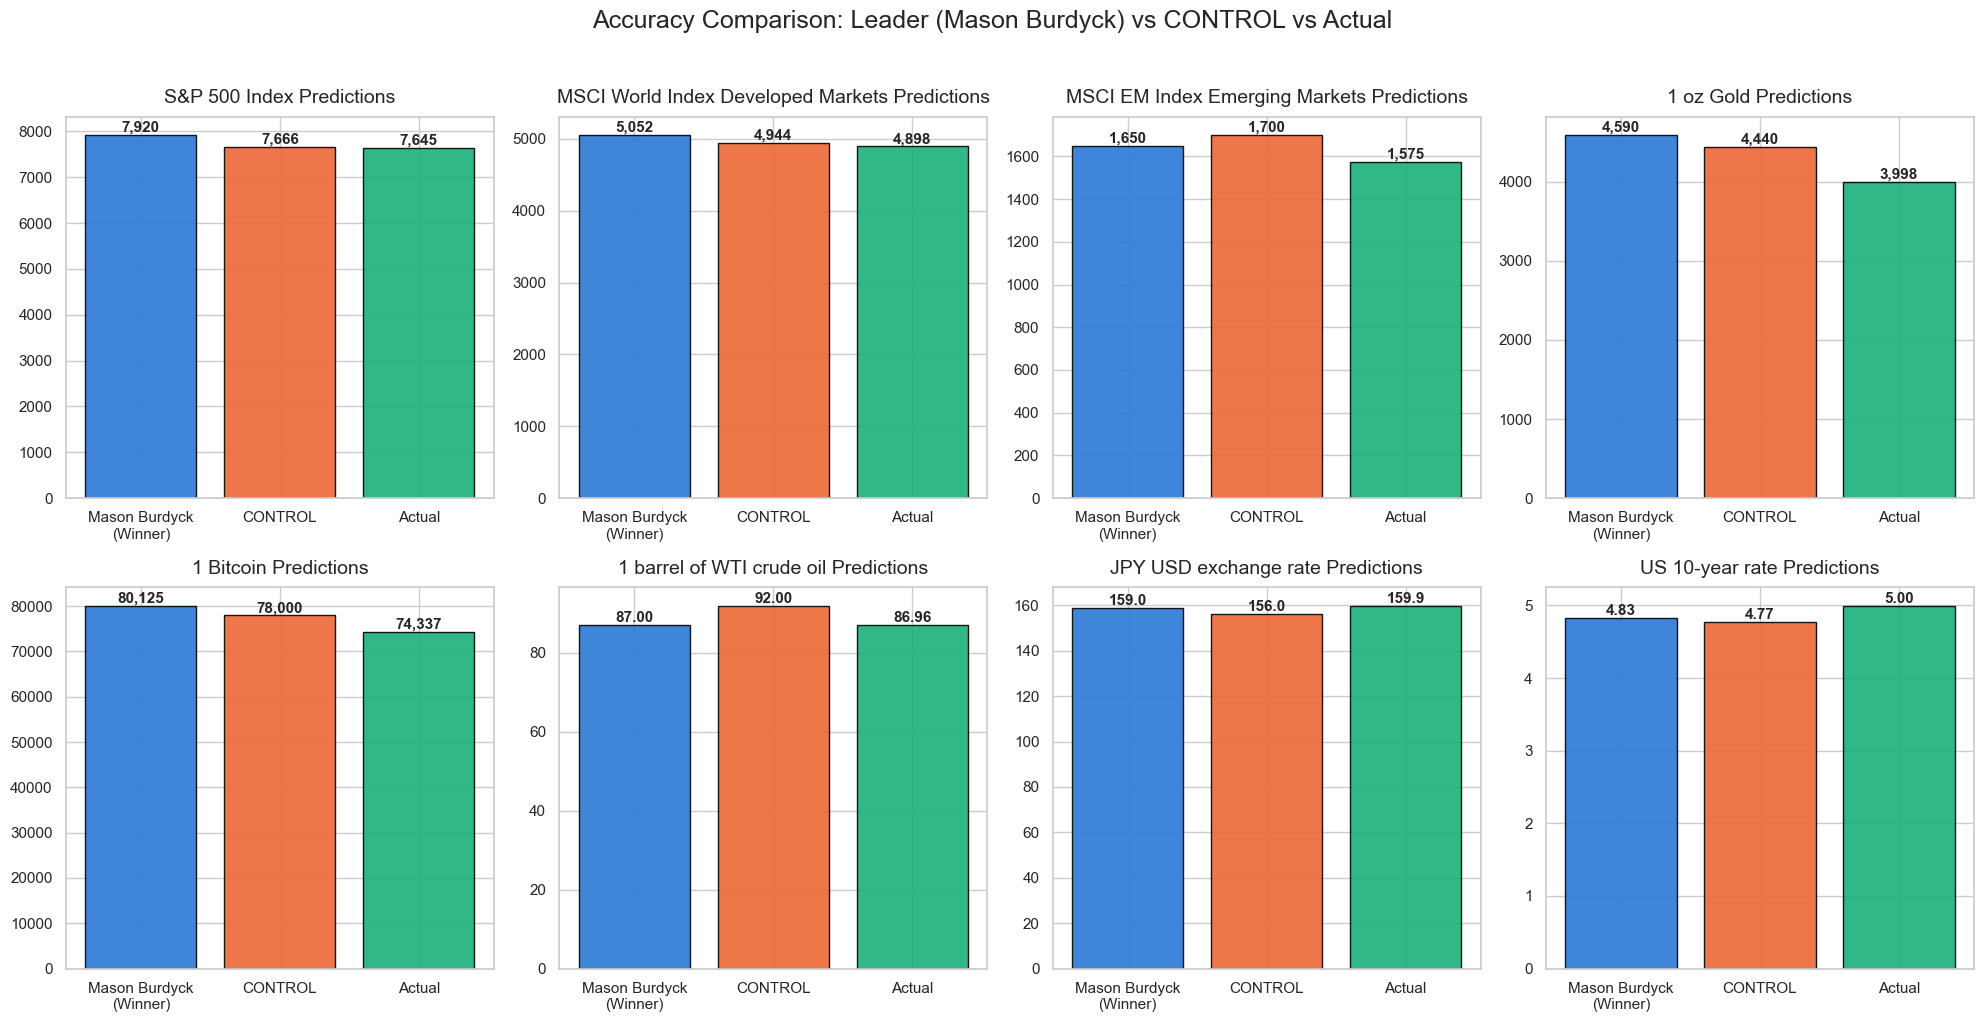

In [14]:
# --- VISUALIZATION 4: Winner vs CONTROL vs Actual ---

winner_name = winner  # top non-benchmark participant, from STEP 4 -- avoids a degenerate
                       # CONTROL-vs-CONTROL chart when EXCLUDE_BENCHMARK_FROM_RANKS is set
has_control = "CONTROL" in results_df.index

winner_preds, control_preds = [], []
for asset in assets:
    pred_col = f"{asset}_Pred"
    winner_preds.append(results_df.loc[winner_name, pred_col])
    control_preds.append(results_df.loc["CONTROL", pred_col] if has_control else np.nan)

n_assets = len(assets)
n_cols = min(4, n_assets)
n_rows = math.ceil(n_assets / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
axes = np.atleast_1d(axes).flatten()

labels = [f"{winner_name}\n(Winner)", "CONTROL", "Actual"]

for i, asset in enumerate(assets):
    ax = axes[i]
    actual_price = ACTUAL_PRICES.get(asset)

    if actual_price is None:
        ax.text(0.5, 0.5, "Data Not Available", ha="center", va="center")
        ax.set_title(f"{asset} Predictions", fontsize=14, pad=10)
        continue

    values = [winner_preds[i], control_preds[i], actual_price]
    bars = ax.bar(labels, values, color=CAT_COLORS, edgecolor="black", alpha=0.9)
    ax.set_title(f"{asset} Predictions", fontsize=14, pad=10)

    for bar in bars:
        height = bar.get_height()
        if np.isnan(height):
            continue
        text_val = f"{height:,.0f}" if height > 1000 else f"{height:,.1f}" if height > 100 else f"{height:,.2f}"
        ax.text(bar.get_x() + bar.get_width() / 2.0, height, text_val,
                ha="center", va="bottom", fontsize=11, fontweight="bold")

for j in range(n_assets, len(axes)):
    axes[j].axis("off")

plt.suptitle(f"Accuracy Comparison: Leader ({winner_name}) vs CONTROL vs Actual", fontsize=18, y=1.02)
plt.tight_layout()
plt.savefig(RESULTS_DIR / f"winner_vs_control_vs_actual_{DATE_STAMP}.png", dpi=150, bbox_inches="tight")
plt.show()

[RECOVERY NOTE: this cell sat between Visualization 4 and the "SAVE ALL RESULTS" cell in the original notebook. Its content was never printed or read during our conversation, so it could not be reconstructed -- this is a placeholder only. Based on the notebook's pattern (a short markdown header/note ahead of each major section), it likely introduced the save step, but that is a guess, not recovered content.]

In [15]:
# --- SAVE ALL RESULTS (leaderboard, standings, charts) TO results/ ---

leaderboard_path = RESULTS_DIR / f"full_leaderboard_{DATE_STAMP}.csv"
results_df[display_cols].to_csv(leaderboard_path)

standings_path = RESULTS_DIR / f"rank_standings_{DATE_STAMP}.csv"
rank_standings.to_csv(standings_path)

chart_filenames = [
    f"prediction_error_heatmap_{DATE_STAMP}.png",
    f"rank_heatmap_{DATE_STAMP}.png",
    f"prediction_distributions_{DATE_STAMP}.png",
    f"winner_vs_control_vs_actual_{DATE_STAMP}.png",
]
missing_charts = [name for name in chart_filenames if not (RESULTS_DIR / name).exists()]
if missing_charts:
    print("Warning: missing charts — run the visualization cells above first:")
    for name in missing_charts:
        print(f" - {name}")

print(f"Saved to {RESULTS_DIR.resolve()}:")
print(f" - {leaderboard_path.name}")
print(f" - {standings_path.name}")
for name in chart_filenames:
    if name not in missing_charts:
        print(f" - {name}")

Saved to /Users/gunnarbalch/PycharmProjects/Jupyter/Student Predictions/results:
 - full_leaderboard_2026-11-11.csv
 - rank_standings_2026-11-11.csv
 - prediction_error_heatmap_2026-11-11.png
 - rank_heatmap_2026-11-11.png
 - prediction_distributions_2026-11-11.png
 - winner_vs_control_vs_actual_2026-11-11.png
